# Mental Health Clinical Trials: Machine Learning

A follow-up to `01_trials_pipeline.ipynb`. It reuses the clean tables in `data/clean/` and asks three questions with scikit-learn:

* **F. Checking the grouping rules:** Can a text classifier, trained on the rule-based condition groups, find condition names the rules handle wrongly?
* **G. Predicting which trials stop early:** Can registration details (phase, sponsor, conditions, treatments, countries) predict whether a trial is terminated rather than completed?
* **H. Topics in trial titles:** What treatment approaches appear in trial titles, and which grew between 2010–12 and 2023–25?

Run the cells in order after `01_trials_pipeline.ipynb`. It works in Colab (Google Drive) or locally from the project folder. Results refer to the download of 1 October 2026.

## Setup

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

try:                                   # Colab: use the project folder in Google Drive
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = '/content/drive/MyDrive/mental-health-trials-pipeline'
except ImportError:                    # locally: run from the project folder
    PROJECT = '.'
for sub in ['results/ml', 'images/ml']:
    os.makedirs(f'{PROJECT}/{sub}', exist_ok=True)

# keep_default_na=False so the phase value "NA" (not applicable) isn't read as missing
read = lambda name: pd.read_csv(f'{PROJECT}/data/clean/{name}.csv', keep_default_na=False, na_values=[''])
trials, conditions, interventions, sites = (read(n) for n in ['trials', 'conditions', 'interventions', 'sites'])
SEED = 42
for n, df in [('trials', trials), ('conditions', conditions), ('interventions', interventions), ('sites', sites)]:
    print(f'{n:14s} {len(df):>7,} rows')

trials          18,357 rows
conditions      40,636 rows
interventions   32,628 rows
sites           20,028 rows


## F. Checking the grouping rules with a text classifier

The pipeline groups each listed condition with keyword rules (C2). Here a classifier learns those groups from the condition text alone, using word and character n-grams (TF-IDF) and logistic regression. Every prediction is made by a model that never saw that condition name (5-fold cross-validation).

The rules are the labels, so the model mostly copies them. The useful part is where it **disagrees**: either the model is wrong, or the rules miss a spelling, word order or synonym. Disagreements are listed with how many trials use that condition name, so the most consequential ones come first.

**F1.** One row per distinct condition name (case-insensitive), with the number of trials that list it.

In [2]:
conditions['key'] = conditions['condition'].str.lower().str.strip()
names = (conditions.groupby('key')
         .agg(condition=('condition', 'first'), rule_group=('condition_group', 'first'),
              n_trials=('nct_id', 'nunique'))
         .reset_index())
print(len(names), 'distinct condition names')
print(names['rule_group'].value_counts().to_string())

7531 distinct condition names
rule_group
Other                        6246
Depression                    397
Anxiety                       251
Schizophrenia & psychosis     221
Substance use                 173
PTSD                           86
Eating disorders               68
Bipolar disorder               65
OCD                            24


**F2.** Cross-validated predictions and agreement with the rules.

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline, make_union

text_model = make_pipeline(
    make_union(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True),                      # words
               TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 5), sublinear_tf=True)),  # spelling variants
    LogisticRegression(C=10, max_iter=3000, class_weight='balanced'))

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
proba = cross_val_predict(text_model, names['key'], names['rule_group'], cv=cv, method='predict_proba')
classes = np.unique(names['rule_group'])
names['model_group'] = classes[proba.argmax(axis=1)]
names['model_prob'] = proba.max(axis=1).round(3)

report = classification_report(names['rule_group'], names['model_group'], digits=3, output_dict=True)
pd.DataFrame(report).T.round(3).to_csv(f'{PROJECT}/results/ml/F_condition_classifier_report.csv')
print(classification_report(names['rule_group'], names['model_group'], digits=3))

                           precision    recall  f1-score   support

                  Anxiety      0.920     0.960     0.940       251
         Bipolar disorder      0.970     0.985     0.977        65
               Depression      0.985     0.975     0.980       397
         Eating disorders      0.776     0.971     0.863        68
                      OCD      0.955     0.875     0.913        24
                    Other      0.995     0.987     0.991      6246
                     PTSD      0.903     0.977     0.939        86
Schizophrenia & psychosis      0.986     0.991     0.989       221
            Substance use      0.862     0.977     0.916       173

                 accuracy                          0.985      7531
                macro avg      0.928     0.966     0.945      7531
             weighted avg      0.986     0.985     0.985      7531



**F3.** Where the model and the rules disagree, most-used condition names first.

In [4]:
dis = (names[names['model_group'] != names['rule_group']]
       .sort_values(['n_trials', 'model_prob'], ascending=False)
       [['condition', 'n_trials', 'rule_group', 'model_group', 'model_prob']])
dis.to_csv(f'{PROJECT}/results/ml/F_condition_disagreements.csv', index=False)
print(f'{len(dis)} of {len(names)} names disagree ({dis.n_trials.sum()} trial listings)')
pd.set_option('display.width', 200); pd.set_option('display.max_colwidth', 60)
print(dis.head(40).to_string(index=False))

116 of 7531 names disagree (807 trial listings)
                         condition  n_trials    rule_group      model_group  model_prob
                    Dental Anxiety       167         Other          Anxiety       0.989
              Preoperative Anxiety        60         Other          Anxiety       0.918
                         Anhedonia        53    Depression            Other       0.953
                     Kinesiophobia        50         Other          Anxiety       0.845
                Procedural Anxiety        45         Other          Anxiety       0.998
                               MDD        39    Depression            Other       0.976
            Respiratory Depression        36         Other       Depression       0.909
                               OCD        25           OCD            Other       0.517
                        Alcoholism        22 Substance use            Other       0.955
                   Eating Behavior        18         Other Eating disord

**F4.** One disagreement ("Bipolar Affective Disorder, Currently Depressed": rules say Depression, model says Bipolar) points to a rule-order issue: Depression is checked before Bipolar disorder, so any name containing both goes to Depression. How many condition names and trials does that affect?

In [5]:
bip = conditions[conditions['key'].str.contains(r'bipolar|bi-polar|manic')
                 & (conditions['condition_group'] != 'Bipolar disorder')]
print(bip.groupby(['condition', 'condition_group'])['nct_id'].nunique()
         .sort_values(ascending=False).head(10).to_string())
bip_ids = set(bip['nct_id'])
grouped_bipolar = set(conditions.loc[conditions['condition_group'] == 'Bipolar disorder', 'nct_id'])
print(f'\nTrials listing a bipolar-named condition outside the Bipolar group: {len(bip_ids)}; '
      f'of these, {len(bip_ids - grouped_bipolar)} have no other condition in the Bipolar group')

condition                                                  condition_group
Bipolar Depression                                         Depression         118
Depression, Bipolar                                        Depression          23
Bipolar Disorder Depression                                Depression           6
Bipolar II Disorder, Most Recent Episode Major Depressive  Depression           3
Bipolar I Depression                                       Depression           3
Bipolar Depression Depressed Phase                         Depression           2
Depressive Episodes, Bipolar I Depression                  Depression           2
Bi-Polar Disorder                                          Other                2
Bipolar Affective Disorder, Currently Depressed, Moderate  Depression           2
Manic Depression                                           Depression           2

Trials listing a bipolar-named condition outside the Bipolar group: 174; of these, 139 have no other con

### Findings: grouping rules

* The classifier agreed with the rules on **98.5%** of 7,531 distinct condition names (macro F1 0.95), so the rules are internally consistent.
* The 116 disagreements (807 trial listings) fall into three kinds:
  * **Deliberate exclusions working as intended.** The largest disagreements are names the rules exclude on purpose: dental anxiety (167 trials), preoperative and procedural anxiety, kinesiophobia, respiratory depression. The model can't see the exclusion list, so these confirm the exclusions rather than reveal errors.
  * **Model errors.** Short acronyms and single words the rules match correctly (MDD, OCD, GAD, anhedonia, alcoholism) and everyday eating terms that aren't eating disorders (healthy eating, picky eating, time-restricted eating).
  * **Candidate rule gaps.** Names a clinician would group but the rules miss because of word order, punctuation or synonyms: "Stress Disorders, Traumatic" and "Traumatic Stress Disorder" (PTSD); "Alcohol-Related Disorders", "Drug Use", "Cannabis Abuse", "Amphetamine Abuse" (substance use); "Eating, Binge" and "Avoidant / Restrictive Food Intake Disorder" (eating disorders); "Bi-Polar Disorder". Most are rare (1–15 trials each), and many trials also list another condition that is already grouped.
* **Rule order (F4):** 174 trials list a bipolar-named condition (mostly "Bipolar Depression", 118 trials) that is grouped as Depression because Depression is checked first; **139** of them have no other condition in the Bipolar group. This is the largest gap found, and it was spotted from a single low-frequency disagreement.
* Tobacco and nicotine use are not in the Substance use rules. Whether they belong there is a scope decision rather than an error.
* None of these changes is applied here; the counts in `01_trials_pipeline.ipynb` are unchanged.

## G. Predicting which trials stop early

**Question:** Using only information known when a trial is registered, can we predict whether it will be **terminated** rather than **completed**?

* **Trials:** In-scope trials that are completed or terminated. Withdrawn trials (stopped before enrolling anyone) and suspended trials are left out, because their registry records are often incomplete.
* **Leakage check:** `enrollment` is excluded. For ended trials it is the *actual* number enrolled, which is much lower for terminated trials (median 17 vs 71), so it reveals the outcome rather than predicting it. G4 shows what happens if it is included.
* **Class imbalance:** Only about 8% of these trials were terminated, so accuracy is misleading (predicting "completed" for everyone scores 92%). Models are compared on ROC AUC and average precision, and logistic regression and gradient boosting use `class_weight='balanced'`.

**G1.** One row per trial with its features.

In [6]:
d = trials[(trials['in_scope'] == 1) & trials['overall_status'].isin(['COMPLETED', 'TERMINATED'])].copy()
d['terminated'] = (d['overall_status'] == 'TERMINATED').astype(int)

def flags(df, col, prefix):
    out = df.assign(v=1).pivot_table(index='nct_id', columns=col, values='v', aggfunc='max')
    out.columns = [prefix + re.sub(r'[^a-z]+', '_', str(c).lower()).strip('_') for c in out.columns]
    return out

cond_flags = flags(conditions[conditions['condition_group'] != 'Other'], 'condition_group', 'cond_')
int_flags = flags(interventions, 'intervention_type', 'int_')
cls = interventions.groupby('nct_id')['psychedelic_class']
counts = pd.DataFrame({
    'n_conditions': conditions.groupby('nct_id').size(),
    'n_interventions': interventions.groupby('nct_id').size(),
    'psychedelic': cls.apply(lambda x: (x == 'Psychedelic / MDMA').any()).astype(int),
    'ketamine': cls.apply(lambda x: (x == 'Ketamine / esketamine').any()).astype(int),
    'n_countries': sites.groupby('nct_id')['country'].nunique(),
    'us_site': sites.groupby('nct_id')['country'].apply(lambda x: (x == 'United States').any()).astype(int),
    'canada_site': sites.groupby('nct_id')['country'].apply(lambda x: (x == 'Canada').any()).astype(int),
})
d = d.set_index('nct_id').join(cond_flags).join(int_flags).join(counts)

CAT = ['phase', 'sponsor_class']
NUM = ['start_year', 'n_conditions', 'n_interventions', 'n_countries']
BIN = list(cond_flags.columns) + list(int_flags.columns) + ['psychedelic', 'ketamine', 'us_site', 'canada_site']
d[BIN] = d[BIN].fillna(0)
d['phase'] = d['phase'].fillna('NA')
X, y = d[CAT + NUM + BIN], d['terminated']
print(f'{len(d):,} trials; {y.sum()} terminated ({y.mean():.1%})')
print('Features:', len(CAT + NUM + BIN))

9,463 trials; 771 terminated (8.1%)
Features: 29


**G2.** Preprocessing inside a pipeline, so it is learned from training data only: one-hot encoding for phase and sponsor type (rare categories pooled), median imputation and scaling for counts, and binary flags passed through. The data are split 80/20 (stratified); each model is tuned with 5-fold cross-validation on the training set and scored once on the test set.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import average_precision_score, balanced_accuracy_score, roc_auc_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def preprocess(num=NUM):
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30), CAT),
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), num),
        ('bin', 'passthrough', BIN)])

MODELS = {
    'Baseline (always "completed" rate)': (DummyClassifier(strategy='prior'), {}),
    'Logistic regression': (LogisticRegression(max_iter=3000, class_weight='balanced'),
                            {'model__C': [0.1, 1, 10]}),
    'Gradient boosting': (HistGradientBoostingClassifier(class_weight='balanced', learning_rate=0.05,
                                                          max_iter=200, random_state=SEED),
                          {'model__max_depth': [2, 3, None], 'model__min_samples_leaf': [20, 100]}),
    'Neural network (MLP)': (MLPClassifier(max_iter=400, random_state=SEED),
                             {'model__hidden_layer_sizes': [(16,), (32,)], 'model__alpha': [0.1, 1.0, 3.0]}),
}

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
fitted, rows = {}, []
for name, (model, grid) in MODELS.items():
    search = GridSearchCV(Pipeline([('prep', preprocess()), ('model', model)]), grid or {'model__strategy': ['prior']},
                          scoring='average_precision', cv=cv, n_jobs=-1).fit(X_tr, y_tr)
    est = fitted[name] = search.best_estimator_
    p = est.predict_proba(X_te)[:, 1]
    rows.append({'model': name, 'cv_average_precision': round(search.best_score_, 3),
                 'test_roc_auc': round(roc_auc_score(y_te, p), 3),
                 'test_average_precision': round(average_precision_score(y_te, p), 3),
                 'test_balanced_accuracy': round(balanced_accuracy_score(y_te, est.predict(X_te)), 3),
                 'best_settings': {k.replace('model__', ''): v for k, v in search.best_params_.items()}})
results = pd.DataFrame(rows)
results.to_csv(f'{PROJECT}/results/ml/G_stopped_early_models.csv', index=False)
print(results.drop(columns='best_settings').to_string(index=False))
print('\nBest settings:'); [print(' ', r.model, r.best_settings) for r in results.itertuples()]

                             model  cv_average_precision  test_roc_auc  test_average_precision  test_balanced_accuracy
Baseline (always "completed" rate)                 0.082         0.500                   0.081                    0.50
               Logistic regression                 0.153         0.659                   0.140                    0.62
                 Gradient boosting                 0.171         0.673                   0.151                    0.63
              Neural network (MLP)                 0.161         0.670                   0.150                    0.50

Best settings:
  Baseline (always "completed" rate) {'strategy': 'prior'}
  Logistic regression {'C': 0.1}
  Gradient boosting {'max_depth': 2, 'min_samples_leaf': 20}
  Neural network (MLP) {'alpha': 0.1, 'hidden_layer_sizes': (16,)}


[None, None, None, None]

**G3.** Test-set detail for the best model: ROC curves for all models, the confusion matrix at the default threshold, and which features matter (permutation importance on the test set: the drop in average precision when a feature is shuffled).

Best model on test average precision: Gradient boosting
              precision    recall  f1-score   support

   Completed      0.948     0.682     0.793      1739
  Terminated      0.139     0.578     0.224       154

    accuracy                          0.674      1893
   macro avg      0.543     0.630     0.508      1893
weighted avg      0.882     0.674     0.747      1893



        feature  importance     sd
        us_site      0.0205 0.0056
    canada_site      0.0085 0.0040
 int_behavioral      0.0075 0.0084
          phase      0.0070 0.0046
     int_device      0.0064 0.0040
     start_year      0.0044 0.0030
n_interventions      0.0043 0.0048
       int_drug      0.0035 0.0086
   cond_anxiety      0.0022 0.0024
  sponsor_class      0.0021 0.0008


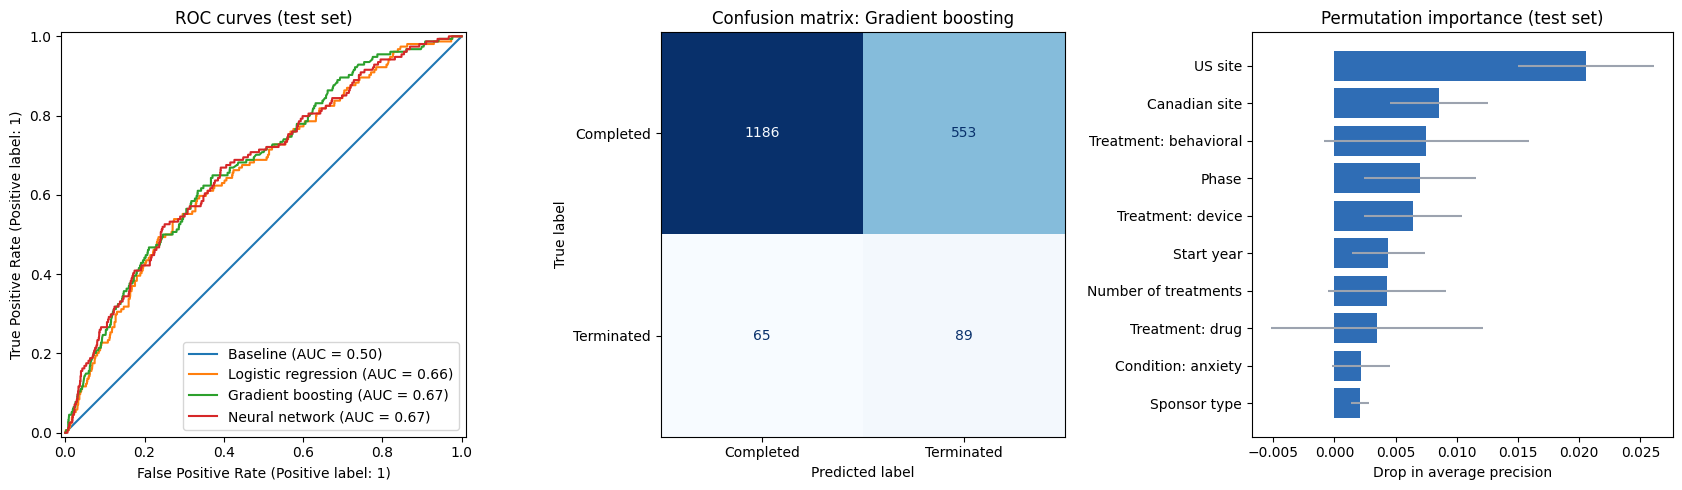

In [8]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

best = results.iloc[1:].sort_values('test_average_precision', ascending=False)['model'].iloc[0]
print('Best model on test average precision:', best)
print(classification_report(y_te, fitted[best].predict(X_te), target_names=['Completed', 'Terminated'], digits=3))

imp = permutation_importance(fitted[best], X_te, y_te, scoring='average_precision',
                             n_repeats=30, random_state=SEED, n_jobs=-1)
imp = (pd.DataFrame({'feature': X.columns, 'importance': imp.importances_mean, 'sd': imp.importances_std})
       .sort_values('importance', ascending=False))
imp.round(4).to_csv(f'{PROJECT}/results/ml/G_stopped_early_importance.csv', index=False)
print(imp.head(10).round(4).to_string(index=False))

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for name, est in fitted.items():
    RocCurveDisplay.from_estimator(est, X_te, y_te, ax=ax[0], name=name.split(' (')[0])
ax[0].set_title('ROC curves (test set)')
ConfusionMatrixDisplay.from_estimator(fitted[best], X_te, y_te, display_labels=['Completed', 'Terminated'],
                                      ax=ax[1], cmap='Blues', colorbar=False)
ax[1].set_title(f'Confusion matrix: {best}')
PRETTY = {'us_site': 'US site', 'canada_site': 'Canadian site', 'phase': 'Phase', 'sponsor_class': 'Sponsor type',
          'start_year': 'Start year', 'n_interventions': 'Number of treatments', 'n_conditions': 'Number of conditions',
          'n_countries': 'Number of countries', 'psychedelic': 'Psychedelic / MDMA', 'ketamine': 'Ketamine'}
pretty = lambda f: PRETTY.get(f, f.replace('int_', 'Treatment: ').replace('cond_', 'Condition: ').replace('_', ' '))
top = imp.head(10).iloc[::-1]
ax[2].barh(top['feature'].map(pretty), top['importance'], xerr=top['sd'], color='#2f6db5', ecolor='#9ca3af')
ax[2].set(title='Permutation importance (test set)', xlabel='Drop in average precision')
fig.tight_layout()
fig.savefig(f'{PROJECT}/images/ml/stopped_early.png', dpi=150, bbox_inches='tight')
plt.show()

**G4.** Leakage check: the same best model with `enrollment` added.

In [9]:
leaky = Pipeline([('prep', preprocess(NUM + ['enrollment'])), ('model', fitted[best].named_steps['model'])])
leaky.fit(d.loc[X_tr.index, CAT + NUM + BIN + ['enrollment']], y_tr)
p = leaky.predict_proba(d.loc[X_te.index, CAT + NUM + BIN + ['enrollment']])[:, 1]
print(f'With enrollment: test ROC AUC {roc_auc_score(y_te, p):.3f}, average precision {average_precision_score(y_te, p):.3f}')
print('Median enrollment:', d.groupby('terminated')['enrollment'].median().rename({0: 'completed', 1: 'terminated'}).to_dict())

With enrollment: test ROC AUC 0.804, average precision 0.384
Median enrollment: {'completed': 71.0, 'terminated': 17.0}


### Findings: predicting early stopping

* **Registration details predict early stopping only weakly.** The best model, gradient boosting, reached a test ROC AUC of 0.67 and average precision of 0.15, against 0.50 and 0.08 for the baseline. Logistic regression (0.66) and the neural network (0.67) were essentially tied, so the limit is the information available, not the algorithm.
* **At the default threshold** gradient boosting flagged 58% of terminated trials, but only 14% of the trials it flagged were actually terminated: useful for screening a shortlist, not for confident prediction. The neural network, which has no class weighting, predicted "completed" for every trial at the default threshold (balanced accuracy 0.50), even though it ranked trials about as well as the others.
* **What the model used:** A US site, a Canadian site, drug or device treatments and later-phase designs went with more terminations (for example 14% of drug trials vs 6% of others; 16% of phase 2–4 trials vs 6% of trials with no phase), and behavioural treatments with fewer (5% vs 11%).
* **Caveat on the US effect:** Trials without a US site are far more often left with an "Unknown" status (23% vs 5% of trials started by 2020), so some of their terminations are probably never recorded. Part of the US effect is likely a reporting difference rather than a real one.
* **Leakage check:** Adding `enrollment` raised the test ROC AUC from 0.67 to 0.80, because for ended trials it is the actual number enrolled (median 17 terminated vs 71 completed). It reveals the outcome rather than predicting it, which is why it is excluded.

## H. Topics in trial titles

Topic modelling finds groups of words that tend to appear together, without any labels. Condition names (depression, PTSD, schizophrenia, …) are removed first, because the condition groups already cover them; what remains describes **how** conditions are being treated or studied. Non-negative matrix factorisation (NMF) on TF-IDF title features finds 16 topics; each trial is assigned its strongest topic, or none if no topic is clearly present.

**H1.** Fit the topics and list each topic's top words.

In [10]:
from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

GENERIC = '''study trial trials effect effects effectiveness efficacy safety randomized randomised controlled pilot
patients patient adults adult treatment treatments evaluation evaluate evaluating clinical versus vs use using based
comparison compare comparing feasibility phase impact people individuals participants subjects healthy volunteers
open label double blind placebo multicenter care intervention interventions program programme disorder disorders
symptoms improve improving reduce reducing group'''.split()
CONDITION_WORDS = '''depression depressive depressed major mdd anxiety social generalized schizophrenia schizoaffective
bipolar ptsd posttraumatic traumatic post stress ocd obsessive compulsive anorexia bulimia nervosa binge eating alcohol
opioid opioids cocaine cannabis substance methamphetamine dependence psychosis psychotic resistant veterans postpartum
children adolescents adolescent youth women older disease related illness severe mood mental health'''.split()

scope = trials[trials['in_scope'] == 1].copy()
vec = TfidfVectorizer(stop_words=list(ENGLISH_STOP_WORDS | set(GENERIC) | set(CONDITION_WORDS)),
                      ngram_range=(1, 2), min_df=5, max_df=0.3, sublinear_tf=True)
T = vec.fit_transform(scope['title'].fillna(''))
words = np.array(vec.get_feature_names_out())
nmf = NMF(n_components=16, init='nndsvda', random_state=SEED, max_iter=800)
W = nmf.fit_transform(T)

def label(comp, n=3):        # name each topic by its top single words
    out = []
    for w in words[comp.argsort()[::-1]]:
        if ' ' not in w and w not in out:
            out.append(w)
        if len(out) == n:
            break
    return ', '.join(out)

topics = pd.DataFrame({'topic': range(nmf.n_components),
                       'label': [label(c) for c in nmf.components_],
                       'top_words': [', '.join(words[c.argsort()[::-1][:10]]) for c in nmf.components_]})
topics.to_csv(f'{PROJECT}/results/ml/H_title_topics.csv', index=False)
print(topics[['topic', 'top_words']].to_string(index=False))

 topic                                                                                                                                                    top_words
     0 behavioral, cognitive behavioral, cognitive, behavioral therapy, activation, behavioral activation, therapy, remediation, cognitive remediation, therapy cbt
     1           magnetic, magnetic stimulation, transcranial magnetic, transcranial, stimulation, repetitive, repetitive transcranial, rtms, stimulation rtms, tms
     2                              virtual, reality, virtual reality, reality exposure, reality glasses, glasses, reality pain, vr, distraction, immersive virtual
     3                     therapy, cognitive, acceptance, cognitive therapy, commitment, commitment therapy, acceptance commitment, music therapy, music, behavior
     4                      training, cognitive, cognitive training, attention, skills, control, remediation, cognitive remediation, metacognitive training, memory
     5          

**H2.** Each topic's share of trials in 2010–12 and 2023–25 (trials with no clear topic count in the denominator).

No clear topic: 44% of titles
                                             label  share_2010_12  share_2023_25  change_pts
topic                                                                                       
14                  adjunctive, tolerability, term          0.094          0.040      -5.391
0                behavioral, cognitive, activation          0.055          0.034      -2.027
1              magnetic, transcranial, stimulation          0.025          0.016      -0.949
11                        internet, cbt, delivered          0.032          0.023      -0.912
7      ketamine, electroconvulsive, antidepressant          0.015          0.012      -0.374
4                   training, cognitive, attention          0.019          0.021       0.217
10                     exercise, physical, aerobic          0.022          0.025       0.300
13                    exposure, prolonged, written          0.013          0.016       0.333
3                   therapy, cognitive, 

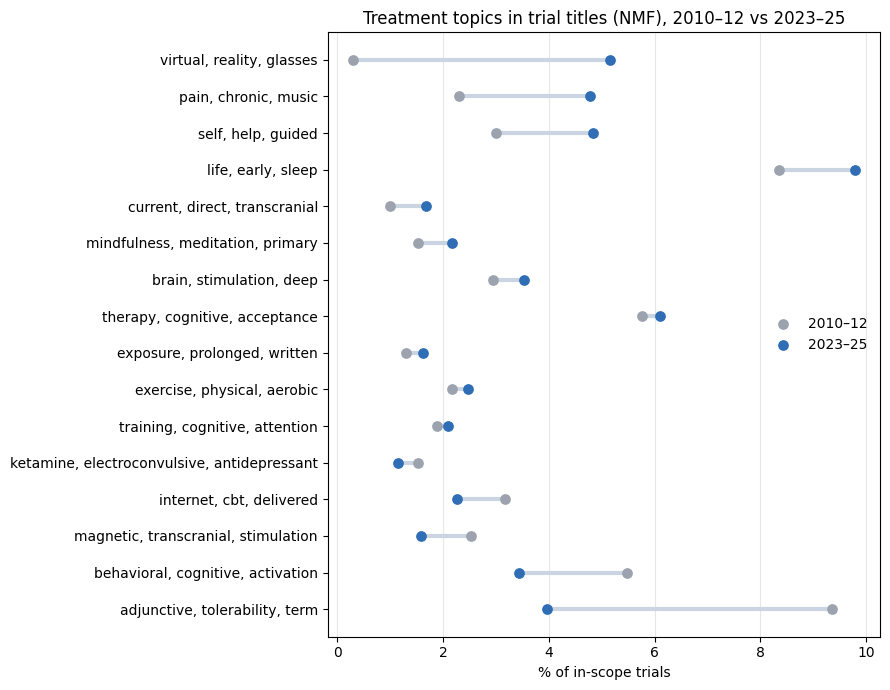

In [11]:
scope['topic'] = np.where(W.max(axis=1) >= 0.02, W.argmax(axis=1), -1)
share = lambda years: scope[scope['start_year'].between(*years)]['topic'].value_counts(normalize=True)
trend = (pd.DataFrame({'share_2010_12': share((2010, 2012)), 'share_2023_25': share((2023, 2025))})
         .drop(index=-1, errors='ignore').fillna(0).join(topics.set_index('topic')['label']))
trend['change_pts'] = (trend['share_2023_25'] - trend['share_2010_12']) * 100
trend = trend.sort_values('change_pts')
trend.round(4).to_csv(f'{PROJECT}/results/ml/H_topic_trends.csv')
print(f"No clear topic: {(scope['topic'] == -1).mean():.0%} of titles")
print(trend[['label', 'share_2010_12', 'share_2023_25', 'change_pts']].round(3).to_string())

fig, ax = plt.subplots(figsize=(9, 7))
yy = np.arange(len(trend))
ax.hlines(yy, trend['share_2010_12'] * 100, trend['share_2023_25'] * 100, color='#cbd5e1', lw=3)
ax.scatter(trend['share_2010_12'] * 100, yy, color='#9ca3af', s=45, label='2010–12', zorder=3)
ax.scatter(trend['share_2023_25'] * 100, yy, color='#2f6db5', s=45, label='2023–25', zorder=3)
ax.set_yticks(yy, trend['label'])
ax.set(xlabel='% of in-scope trials', title='Treatment topics in trial titles (NMF), 2010–12 vs 2023–25')
ax.legend(frameon=False, loc='center right')
ax.grid(axis='x', alpha=0.3)
fig.tight_layout()
fig.savefig(f'{PROJECT}/images/ml/title_topics.png', dpi=150, bbox_inches='tight')
plt.show()

### Findings: title topics

* **Virtual reality was the fastest-growing topic,** from 0.3% of trials in 2010–12 to 5.2% in 2023–25, consistent with the device growth in D3.
* **Pain and procedure-related anxiety** (pain, music, surgery) rose from 2.3% to 4.8%, and **guided self-help, online and mobile** approaches from 3.0% to 4.8%. Mindfulness and transcranial direct-current stimulation (tDCS) also grew slightly.
* **The biggest decline was drug-development language** (adjunctive, tolerability, long-term, pharmacokinetics): from 9.4% to 4.0%, matching the fall in drug and industry share in D3 and D4b. Classic face-to-face cognitive behavioural therapy titles also fell (5.5% to 3.4%), while internet-delivered CBT stayed small.
* **Psychedelics did not form their own topic.** With about 165 in-scope psychedelic trials among 14,713 titles, they are too few for NMF to separate; the keyword flag in C3 remains the better way to track them.
* 44% of titles had no clear topic, mostly short titles naming a drug or a condition only. Topic labels are the top three words of each topic, so they describe rather than define it.